# 14 — Los estados del triage frente a todo el entorno

## Qué contesta este cuaderno

Hasta aquí el entorno se enfrentó al triage **por semanas** (cuadernos 12 y 13) o **mecanismo por
mecanismo** (07, 08, 11). Este cuaderno lo hace de otra forma, a pedido del propietario:

1. Se define el **estado de cada día**: pico, bajo, normal. También la **estabilidad** de cada tramo.
2. Se enfrenta **todo** lo externo a esos estados: clima, vigilancia, seguridad, eventos, fiestas,
   días especiales y ENSO.
3. La granularidad es **año-mes-día, sin hora**, para no empezar demasiado fino.

Se trabaja en conversación: cada sección termina con su lectura, y la última recoge lo que se
concluye entre los dos para decidir **con qué se empieza el modelo de predicción**.

## Método, preregistrado antes de mirar

Está en la fila `estados_diarios` de `patrones/datos/variables.csv` y en `docs/CONTEXTO.md`, con fecha
2026-09-30.

- **El estado no se define sobre el conteo crudo.** Sobre el crudo, los picos son lunes y las bajas
  domingos, y eso es *proyección*. Se quita primero lo que ya explican:
  - el **calendario**: día de la semana, festivo, puente, víspera, día después del festivo,
    quincena, vacaciones escolares, Semana Santa, Navidad, fin de año y regreso a clases;
  - el **nivel de la red**: el año y los escalones de Nueva EPS de `desenlace.py`.
- **La estación se conserva.** El clima y la vigilancia podrían explicarla.
- **Estados**, sobre z = residuo / desviación típica:
  - **pico:** z > +1;
  - **bajo:** z < −1;
  - **normal:** |z| ≤ 0,5;
  - intermedio: el resto.
- **Estabilidad:** la desviación típica móvil del residuo en 14 días. El tercil bajo es estable y
  el alto, agitado.
- **Prueba:** exposición estandarizada ~ 1[pico] + 1[bajo], con errores HAC de 7 días, con y sin mes
  fijo.
  - Benjamini-Hochberg con q = 0,10 dentro de cada familia.
  - Se descubre en 2022-03 a 2024-12 y se confirma en 2025-01 a 2026-09.
  - **Solo cuenta lo que se confirma con el mismo signo y con el mes fijo.**
- **Lo del mismo día es descriptivo.** Para predecir solo sirve lo que ocurre antes.

## De dónde salen los datos

| Familia | Archivo | Qué se usa |
|---|---|---|
| Triage | `salidas/triage_diario.parquet`, `triage_edad.parquet` | conteo diario, bandas de edad |
| Calendario (control) | `calendarios/calendario_Colombia.csv` | festivos, puentes, vacaciones, temporadas |
| Clima | `calendarios/clima_unificado.csv.gz` | temperatura, amplitud, humedad, lluvia (día, 7 y 30 días), radiación, viento |
| Vigilancia | `vigilancia_sivigila.csv.gz`, `vigilancia_sivigila_eventos.csv.gz` | IRA, IRAG, EDA y 5 eventos de Manizales, por semana (hasta 2025-12) |
| Seguridad | `seguridad_mindefensa.csv.gz` | lesiones de tránsito, lesiones personales, homicidio, violencia intrafamiliar |
| Eventos | `eventos_manizales_2020_2026.csv`, `fiestas_caldas_2020_2026.csv`, `desastres_manizales_2020_2026.csv` | Feria y eventos por categoría, fiestas por distancia, desastres |
| Días especiales | `calendario_Colombia.csv` | día de la madre, amor y amistad, velitas, Halloween… (no están en el control) |
| ENSO | `enso_oni.csv` | ONI del mes y de 3 meses antes |

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
GRIS_CLARO = "#d9d8d4"
COLOR_ESTADO = {"pico": ROJO, "intermedio": GRIS_CLARO, "normal": MUDO, "bajo": AZUL}
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
pct = lambda x: (np.exp(x) - 1) * 100
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
SEM = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

INI, FIN = "2022-03-01", "2026-09-20"
DESC, CONF = ("2022-03-01", "2024-12-31"), ("2025-01-01", "2026-09-20")
ESCALONES_RED = ["2024-04-01", "2025-11-15", "2026-03-01", "2026-07-01"]       # desenlace.py
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad", "es_temporada_fin_anio",
       "es_regreso_colegio"]
dias = pd.date_range(INI, FIN)
tri = (pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
         .set_index("dia")["triages"].reindex(dias).astype(float))
tri["2024-03-19":"2024-03-21"] = np.nan                       # caida de registro, no cero pacientes
cal = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
calc = cal[CAL].apply(pd.to_numeric, errors="coerce").fillna(0)
dsem = pd.get_dummies(pd.Index(dias.dayofweek), prefix="d", drop_first=True).set_index(dias).astype(float)
anio = pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)
red = pd.DataFrame({f"red{i}": (dias >= f).astype(float) for i, f in enumerate(ESCALONES_RED)}, index=dias)

def ajusta(Z, y=tri):
    Z = Z.copy(); Z.insert(0, "c", 1.0)
    ly = np.log(y); ok = ly.notna()
    b, *_ = np.linalg.lstsq(Z[ok].values, ly[ok].values, rcond=None)
    return (ly - Z.values @ b).where(ok)

def estados(r):
    z = r / r.std()
    e = pd.Series("intermedio", index=r.index)
    e[z > 1] = "pico"; e[z < -1] = "bajo"; e[z.abs() <= .5] = "normal"; e[z.isna()] = np.nan
    return e

R_nivel = ajusta(pd.concat([anio, red], axis=1))              # solo el nivel: lo que ve el ojo sobre el crudo
R_sem = ajusta(pd.concat([dsem, anio, red], axis=1))          # + dia de la semana
R = ajusta(pd.concat([dsem, calc, anio, red], axis=1))        # control completo
estado, estado_crudo = estados(R), estados(R_nivel)
vol = R.rolling(14, center=True, min_periods=10).std()
print(f"{tri.notna().sum()} días, {dias[0].date()} a {dias[-1].date()}")
print(f"desviación típica del residuo: solo nivel {R_nivel.std():.3f} · + día de semana {R_sem.std():.3f} · + calendario {R.std():.3f}")

1662 días, 2022-03-01 a 2026-09-20
desviación típica del residuo: solo nivel 0.199 · + día de semana 0.131 · + calendario 0.106


---
# 1. Proyección contra predicción: qué queda del pico cuando se quita el calendario

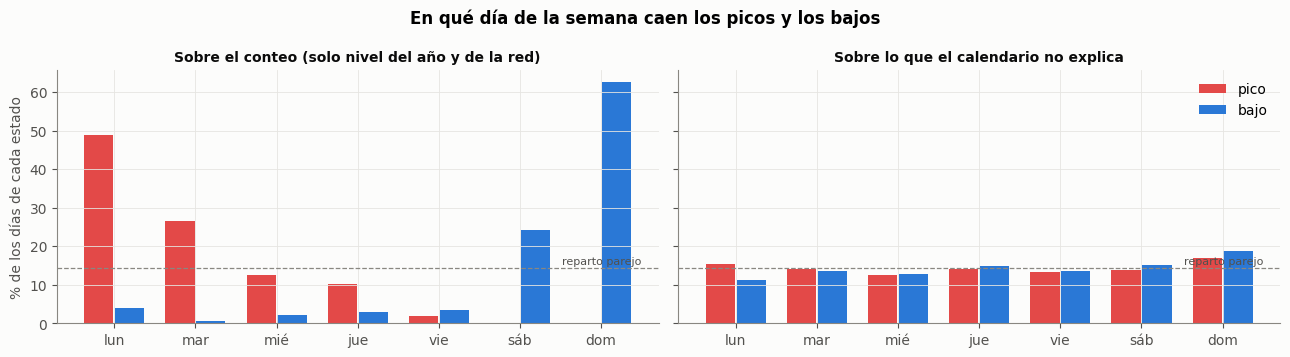

El día de la semana explica el 56.5% de la variación diaria (sin el nivel); con el resto del calendario, el 72.0%.
De 264 picos del conteo, siguen siendo pico 116 (44%). De 297 bajos, siguen 111.


estado sin calendario,bajo,intermedio,normal,pico
estado sobre el conteo,,,,
bajo,111,79,99,8
intermedio,65,153,218,73
normal,74,176,291,51
pico,0,66,82,116


In [2]:
v_sem = 1 - R_sem.var() / R_nivel.var(); v_cal = 1 - R.var() / R_nivel.var()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, e, t in [(axes[0], estado_crudo, "Sobre el conteo (solo nivel del año y de la red)"),
                 (axes[1], estado, "Sobre lo que el calendario no explica")]:
    tab = pd.crosstab(dias.dayofweek, e, normalize="columns") * 100
    for j, (k, col) in enumerate([("pico", ROJO), ("bajo", AZUL)]):
        ax.bar(np.arange(7) + (j - .5) * .38, tab[k].values, width=.36, color=col, label=k)
    ax.axhline(100 / 7, color=MUDO, lw=.9, ls="--"); ax.text(6.5, 100 / 7 + 1, "reparto parejo", ha="right", fontsize=8, color=TINTA2)
    ax.set_xticks(range(7), SEM); ax.set_title(t, fontsize=10)
axes[0].set_ylabel("% de los días de cada estado"); axes[1].legend(loc="upper right")
fig.suptitle("En qué día de la semana caen los picos y los bajos", fontweight="bold"); plt.tight_layout(); plt.show()

cruce = pd.crosstab(estado_crudo.rename("estado sobre el conteo"), estado.rename("estado sin calendario"))
print(f"El día de la semana explica el {v_sem:.1%} de la variación diaria (sin el nivel); con el resto del calendario, el {v_cal:.1%}.")
print(f"De {cruce.loc['pico'].sum()} picos del conteo, siguen siendo pico {cruce.loc['pico','pico']} "
      f"({cruce.loc['pico','pico'] / cruce.loc['pico'].sum():.0%}). De {cruce.loc['bajo'].sum()} bajos, siguen {cruce.loc['bajo','bajo']}.")
cruce

**Lectura.**
- Sobre el conteo, casi la mitad de los picos son lunes (49 %) y el 87 % de los bajos son fin de
  semana. Eso es lo que se proyecta sin pensar.
- **El calendario explica el 72 % de la variación diaria**, y el día de la semana solo, el 57 %.
- **Solo el 44 % de los picos del conteo siguen siendo pico** cuando se quita el calendario.
- Lo que queda **se reparte parejo entre los siete días**: el control hace su trabajo.
- Desde aquí, «pico» significa **un día más alto de lo que su calendario anunciaba**. Es lo que hay
  que predecir.

---
# 2. Los estados: cuánto pesan, cuánto duran y cuándo caen

,días,% de días,desvío medio %,racha media (días),racha máx.,P(mismo estado mañana) %
pico,248,14.9,17.3,1.40,7,28.6
intermedio,474,28.5,0.4,1.39,5,28.3
normal,690,41.5,0.1,1.76,9,43.3
bajo,250,15.0,-15.5,1.31,6,23.6


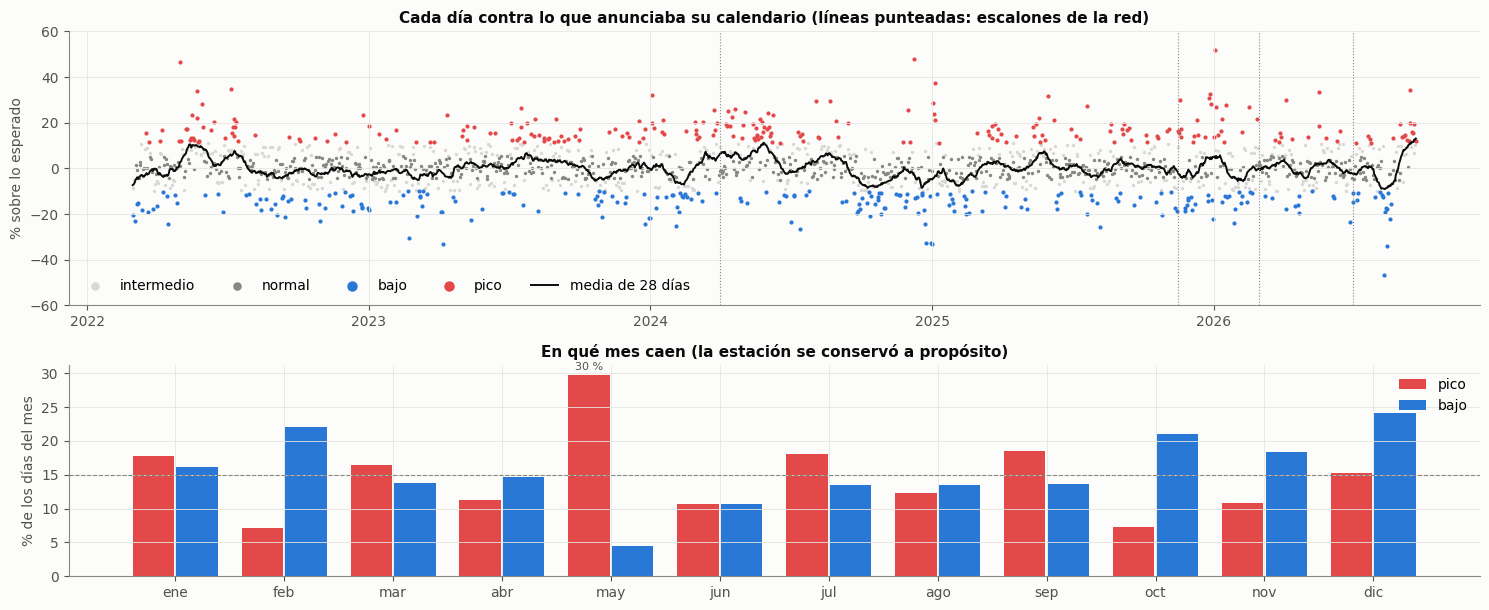

row_0,1,2,3,4,5,6,7,8,9,10,11,12
col_0,,,,,,,,,,,,
pico,17.7,7.1,16.4,11.3,29.7,10.7,18.1,12.3,18.6,7.3,10.8,15.3
normal,31.5,39.8,40.1,45.3,34.8,48.0,41.3,43.9,41.4,43.5,48.3,39.5
bajo,16.1,22.1,13.8,14.7,4.5,10.7,13.5,13.5,13.6,21.0,18.3,24.2


In [3]:
res = pd.DataFrame({"días": estado.value_counts(), "% de días": (estado.value_counts(normalize=True) * 100).round(1),
                    "desvío medio %": R.groupby(estado).mean().pipe(pct).round(1)}).loc[["pico", "intermedio", "normal", "bajo"]]
e = estado.fillna("na"); g = (e != e.shift()).cumsum()
rachas = e.groupby(g).agg(["first", "size"]).query("first != 'na'")
res["racha media (días)"] = rachas.groupby("first")["size"].mean().round(2)
res["racha máx."] = rachas.groupby("first")["size"].max()
res["P(mismo estado mañana) %"] = [round(100 * ((estado == k) & (estado.shift(-1) == k)).sum() / (estado == k).sum(), 1) for k in res.index]
display(res)

fig, axes = plt.subplots(2, 1, figsize=(15, 6.2), gridspec_kw={"height_ratios": [1.3, 1]})
ax = axes[0]
for k in ["intermedio", "normal", "bajo", "pico"]:
    m = (estado == k).values
    ax.scatter(dias[m], pct(R[m]), s=6 if k in ("normal", "intermedio") else 9, color=COLOR_ESTADO[k], label=k, lw=0)
ax.plot(dias, pct(R.rolling(28, center=True, min_periods=14).mean()), color=TINTA, lw=1.4, label="media de 28 días")
for f in ESCALONES_RED: ax.axvline(pd.Timestamp(f), color=MUDO, lw=.8, ls=":")
ax.set_ylabel("% sobre lo esperado"); ax.set_ylim(-60, 60); ax.legend(ncol=5, loc="lower left", markerscale=2.5)
ax.set_title("Cada día contra lo que anunciaba su calendario (líneas punteadas: escalones de la red)")
ax = axes[1]
tab = pd.crosstab(dias.month, estado, normalize="index") * 100
x = np.arange(12)
ax.bar(x - .2, tab["pico"], width=.38, color=ROJO, label="pico"); ax.bar(x + .2, tab["bajo"], width=.38, color=AZUL, label="bajo")
ax.axhline(15, color=MUDO, lw=.8, ls="--")
i = tab["pico"].values.argmax(); ax.text(i - .2, tab["pico"].max() + .8, f"{tab['pico'].max():.0f} %", ha="center", fontsize=8, color=TINTA2)
ax.set_xticks(x, MESES); ax.set_ylabel("% de los días del mes"); ax.legend(loc="upper right")
ax.set_title("En qué mes caen (la estación se conservó a propósito)")
plt.tight_layout(); plt.show()
tab.round(1)[["pico", "normal", "bajo"]].T

**Lectura.**
- Un pico pesa **+17 %** sobre lo esperado y un bajo **−15,5 %**. El ruido de fondo del día es del
  10,6 %.
- **Los picos son de un día:**
  - la racha media es de 1,4 días;
  - la probabilidad de que mañana también sea pico es del 29 %, **el doble de la base (15 %)** pero
    lejos de una certeza.
  - Hay memoria corta, y la tiene el residuo (autocorrelación +0,26 a 1 día).
- **La estación pesa mucho:**
  - **mayo concentra picos (30 % de sus días)** y casi no tiene bajos (4,5 %);
  - febrero, octubre y diciembre son lo contrario (7 % de picos; 21-24 % de bajos).
  - Es la temporada respiratoria de mitad de año que ya se vio en los cuadernos 02 y 08.

---
# 3. Quién llena el pico: ¿un grupo o todos?

Si el pico fuera epidemiológico (una ola respiratoria), debería cargarse sobre los niños. Si es de
acceso (la red, el sistema, un día raro), debería subir todo el mundo a la vez. Se ajusta el
**mismo control a cada banda de edad** y se mira su desvío en cada estado.

In [4]:
ed = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
E = ed.pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0)
E = E[["0-4", "5-14", "15-44", "45-64", "65-+"]]; E[tri.isna()] = np.nan
Zc = pd.concat([dsem, calc, anio, red], axis=1)
Rb = pd.DataFrame({b: ajusta(Zc, E[b].clip(lower=.5)) for b in E.columns})
desv = pct(Rb.groupby(estado).mean()).loc[["pico", "normal", "bajo"]].round(1)
peso = (E.groupby(estado).mean().T / E.groupby(estado).mean().sum(axis=1)).T.loc[["pico", "normal", "bajo"]].mul(100).round(1)
pd.concat({"desvío sobre lo esperado, %": desv, "peso en el día, %": peso}, axis=1)

desvío sobre lo esperado, %                         peso en el día, %  \
                               0-4  5-14 15-44 45-64  65-+               0-4   
pico                          27.1  23.4  16.7  17.3  16.1               3.6   
normal                        -1.5  -0.4   0.5  -0.2  -0.2               3.3   
bajo                         -15.5 -17.3 -16.0 -14.5 -14.5               3.3   

                               
       5-14 15-44 45-64  65-+  
pico    5.0  53.4  18.4  19.5  
normal  4.8  53.9  18.3  19.7  
bajo    4.8  53.1  18.6  20.1

**Lectura.**
- **En un pico sube todo el mundo:** de +16 % a +27 % en todas las bandas. En un bajo cae todo el
  mundo, de −14 % a −17 %.
- Los niños suben algo más (0-4: +27 %; 5-14: +23 %), pero **la composición del día casi no cambia**:
  la banda de 15-44 años sigue siendo alrededor de la mitad en pico, en normal y en bajo.
- Un pico **no es un grupo que llega**: es la demanda entera que se corre.
- Eso apunta más a **acceso y sistema** que a una ola epidemiológica, que se cargaría sobre un grupo.
  Encaja con que la vigilancia no mueva el total (cuaderno 13).

---
# 4. Estabilidad: ¿cuándo está tranquila la serie y cuándo agitada?

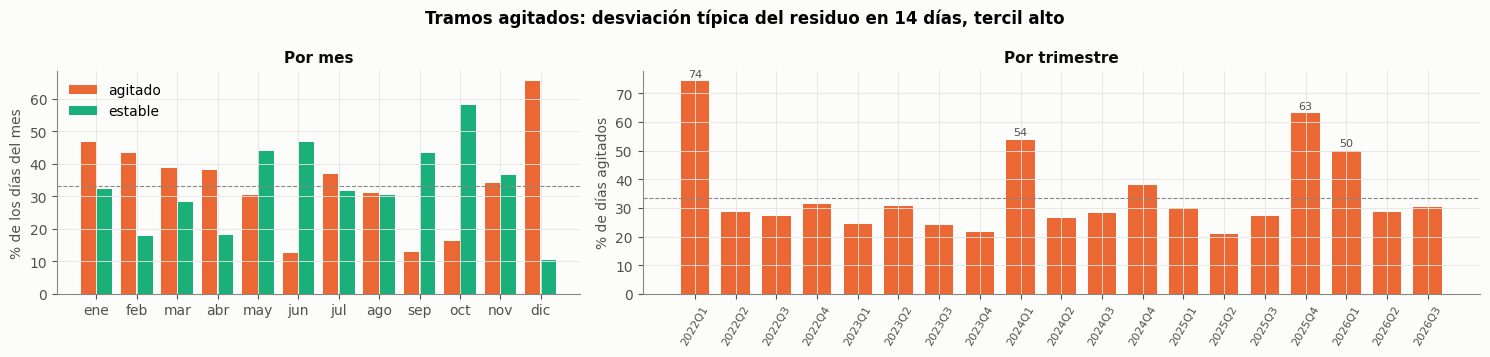

In [5]:
q = vol.quantile([1 / 3, 2 / 3])
ag = pd.cut(vol, [-1, q.iloc[0], q.iloc[1], 9], labels=["estable", "medio", "agitado"])
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
tm = pd.crosstab(dias.month, ag, normalize="index") * 100
axes[0].bar(np.arange(12) - .2, tm["agitado"], width=.38, color=NARANJA, label="agitado")
axes[0].bar(np.arange(12) + .2, tm["estable"], width=.38, color=AQUA, label="estable")
axes[0].axhline(100 / 3, color=MUDO, lw=.8, ls="--"); axes[0].set_xticks(range(12), MESES)
axes[0].set_ylabel("% de los días del mes"); axes[0].legend(); axes[0].set_title("Por mes")
tq = ag.eq("agitado").groupby(dias.to_period("Q")).mean() * 100
axes[1].bar(range(len(tq)), tq.values, color=NARANJA, width=.7)
axes[1].axhline(100 / 3, color=MUDO, lw=.8, ls="--")
axes[1].set_xticks(range(len(tq)), [str(p) for p in tq.index], rotation=60, fontsize=8)
for i in np.argsort(tq.values)[-4:]: axes[1].text(i, tq.values[i] + 1.5, f"{tq.values[i]:.0f}", ha="center", fontsize=8, color=TINTA2)
axes[1].set_ylabel("% de días agitados"); axes[1].set_title("Por trimestre")
fig.suptitle("Tramos agitados: desviación típica del residuo en 14 días, tercil alto", fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura.** La agitación tiene dos fuentes, y ninguna es el clima:
- **La temporada festiva.** Diciembre tiene el 65 % de sus días agitados y enero el 47 %. Es la
  noche festiva del cuaderno 08, que el calendario controla en promedio pero no noche por noche.
- **Los choques de la red:**
  - 2022-T1: el final de la COVID;
  - 2024-T1;
  - **2025-T4 (63 %)**, cuando empiezan los cierres a Nueva EPS;
  - 2026-T1 (50 %).

  Son los trimestres en que el nivel de la red se estaba moviendo.

Lo más estable son junio, septiembre y octubre (13-16 % de días agitados).

---
# 5. Todo el entorno frente a los estados

Para cada exposición y ventana: cuánto se desplaza (en desviaciones típicas) en los días pico y en
los días bajo frente al resto. Se hace en el periodo de descubrir y en el de confirmar, con y sin
el mes fijo.

In [6]:
todos = pd.date_range("2019-12-01", FIN)
VENT = {"t": (0, 0), "t-1a3": (1, 3), "t-4a7": (4, 7), "t-8a14": (8, 14), "t-15a28": (15, 28)}
cols, fam = {}, {}
def pon(k, s, f): cols[k] = s; fam[k] = f

# clima: anomalia contra la climatologia del mes, en ventanas; y cambio a 3 y 7 dias
c = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(todos)
c["amplitud"] = c.temp_max_consenso - c.temp_min_consenso
CLI = {"temp_media": "temp_media_consenso", "temp_min": "temp_min_consenso", "temp_max": "temp_max_consenso",
       "amplitud": "amplitud", "humedad": "humedad_consenso", "lluvia_dia": "precip_consenso_mm",
       "lluvia_7d": "precip_7d", "lluvia_30d": "precip_30d", "radiacion": "radiacion_consenso", "viento": "viento_consenso_ms"}
for nom, col in CLI.items():
    x = c[col].astype(float)
    if nom.startswith("lluvia"): x = np.log1p(x)
    an = x - x.groupby(x.index.month).transform("mean")
    if nom in ("lluvia_7d", "lluvia_30d"):                  # ya son acumulados: tres cortes
        for k, l in {"t-1": 1, "t-8": 8, "t-15": 15}.items(): pon(f"{nom}|{k}", an.shift(l), "clima")
    else:
        for k, (a, b) in VENT.items(): pon(f"{nom}|{k}", an.shift(a).rolling(b - a + 1, min_periods=max(1, (b - a + 1) // 2)).mean(), "clima")
    m3, m7 = x.rolling(3).mean(), x.rolling(7).mean()
    pon(f"{nom}_cambio3|t-1", (m3 - m3.shift(3)).shift(1), "clima")
    pon(f"{nom}_cambio7|t-1", (m7 - m7.shift(7)).shift(1), "clima")

# vigilancia semanal de Manizales: anomalia dentro del anio (conserva la estacion), misma semana y 1-2 antes
v = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"]).query("ambito == 'manizales'")
ev_ = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_eventos.csv.gz", parse_dates=["fecha_inicio_semana"])
ev_ = ev_[ev_.ambito.eq("manizales") & ev_.variable.eq("casos_notificacion")]
VIG = {"ira_total": (v, 995, "consultas_ira_total"), "ira_0_4": (v, 995, "consultas_ira_0_4"),
       "ira_60_mas": (v, 995, "consultas_ira_60_mas"), "irag_hosp": (v, 995, "hospitalizaciones_irag_total"),
       "eda_total": (v, 998, "casos_eda_total"), "consultas_todas": (v, 995, "consultas_todas_causas_total"),
       "agresion_animal_300": (ev_, 300, "casos_notificacion"), "violencia_genero_875": (ev_, 875, "casos_notificacion"),
       "intoxicacion_365": (ev_, 365, "casos_notificacion"), "intento_suicidio_356": (ev_, 356, "casos_notificacion"),
       "varicela_831": (ev_, 831, "casos_notificacion")}
domingo = todos - pd.to_timedelta((todos.dayofweek + 1) % 7, unit="D")
for nom, (df, cod, var) in VIG.items():
    w = df[df.evento.eq(cod) & df.variable.eq(var)].set_index("fecha_inicio_semana")["valor"].astype(float).sort_index()
    w = w[~w.index.duplicated()]
    if cod == 998: w[w.index == pd.Timestamp("2025-12-28")] = np.nan       # SE53-2025 del 998: error de la fuente
    lw = np.log1p(w); an = lw - lw.groupby(lw.index.year).transform("mean")
    for k, l in {"misma_sem": 0, "sem-1": 1, "sem-2": 2}.items():
        pon(f"{nom}|{k}", pd.Series(an.reindex(domingo - pd.Timedelta(weeks=l)).values, index=todos), "vigilancia")

# seguridad MinDefensa, diaria, relativa a su anio
sg = pd.read_csv(RAIZ / "calendarios/seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(todos)
for col in ["lesiones_transito", "lesiones_personales", "homicidio", "violencia_intrafamiliar"]:
    x = sg[col].astype(float); x = x / x.groupby(x.index.year).transform("mean")
    for k, s in {"t": x, "t-1a3": x.shift(1).rolling(3).mean(), "t-4a7": x.shift(4).rolling(4).mean()}.items(): pon(f"{col}|{k}", s, "seguridad")

# eventos de Manizales, fiestas de Caldas por distancia, desastres
def activo(df):
    s = pd.Series(0.0, index=todos)
    for _, r in df.dropna(subset=["fecha_inicio"]).iterrows():
        a = pd.Timestamp(r.fecha_inicio); b = pd.Timestamp(r.fecha_fin) if pd.notna(r.fecha_fin) else a
        s[a:b] += 1
    return s
evm = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv").query("estado in ['realizado', 'programado']")
for cat, g in {"feria": ["feria", "taurino"], "religioso": ["religioso"], "civico": ["civico"],
               "cultural": ["musical", "teatro", "literario", "academico", "universitario"], "deportivo": ["deportivo"]}.items():
    a = activo(evm[evm.categoria.isin(g)]).clip(upper=1)
    pon(f"ev_{cat}|t", a, "eventos"); pon(f"ev_{cat}|t-1a3", a.shift(1).rolling(3).max(), "eventos")
fi = pd.read_csv(RAIZ / "calendarios/fiestas_caldas_2020_2026.csv").query("estado in ['realizado', 'programado']")
for nom, (lo, hi) in {"fiestas_cerca_50km": (0, 50), "fiestas_50a100km": (51, 100), "fiestas_lejos_100km": (101, 999)}.items():
    pon(f"{nom}|t", activo(fi[fi.distancia_km_manizales.between(lo, hi)]).clip(upper=3), "eventos")
pon("desastre_activo|t", activo(pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv")).clip(upper=1), "eventos")

# dias especiales que NO estan en el control
calt = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(todos)
for col in ["es_dia_madre", "es_dia_padre", "es_amor_amistad", "es_semana_amor_amistad", "es_dia_ninez", "es_san_valentin",
            "es_dia_velitas", "es_halloween", "es_temporada_halloween", "es_nochebuena", "es_navidad", "es_ano_viejo",
            "es_reyes_magos", "es_novena", "es_dia_mujer", "es_inicio_mes", "es_fin_mes", "es_fin_semana_largo"]:
    x = pd.to_numeric(calt[col], errors="coerce").fillna(0)
    pon(f"{col}|t", x, "dias_especiales"); pon(f"{col}|t-1", x.shift(1), "dias_especiales")

# ENSO
en = pd.read_csv(RAIZ / "calendarios/enso_oni.csv", parse_dates=["fecha"]); oni = en.set_index(en.fecha.dt.to_period("M"))["oni"]
pon("oni|mes", pd.Series(oni.reindex(todos.to_period("M")).values, index=todos), "enso")
pon("oni|mes-3", pd.Series(oni.reindex((todos - pd.DateOffset(months=3)).to_period("M")).values, index=todos), "enso")

X = pd.DataFrame(cols).reindex(dias); FAM = pd.Series(fam)
print(f"{X.shape[1]} exposiciones:", FAM.value_counts().to_dict())

163 exposiciones: {'clima': 66, 'dias_especiales': 36, 'vigilancia': 33, 'eventos': 14, 'seguridad': 12, 'enso': 2}


In [7]:
MES = pd.get_dummies(pd.Index(dias.month), prefix="m", drop_first=True).set_index(dias).astype(float)
EST = pd.DataFrame({"pico": (estado == "pico").astype(float), "bajo": (estado == "bajo").astype(float)}, index=dias)
EST[estado.isna()] = np.nan

def prueba(x, periodo, con_mes=True):
    xs = (x - X[x.name].mean()) / X[x.name].std()
    D = pd.concat([xs.rename("x"), EST] + ([MES] if con_mes else []), axis=1).loc[slice(*periodo)].dropna()
    if len(D) < 100 or D.x.std() == 0: return None
    Z = D.drop(columns="x"); Z = Z.loc[:, Z.std() > 0].copy(); Z.insert(0, "const", 1.0)
    mc = [k for k in Z if k.startswith("m_")]
    if mc and (Z[mc].sum(axis=1) == 1).all(): Z = Z.drop(columns=mc[0])     # un solo anio sin enero: meses = constante
    if not {"pico", "bajo"} <= set(Z): return None
    r = sm.OLS(D.x, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    return {"pico": r.params["pico"], "p_pico": r.pvalues["pico"], "bajo": r.params["bajo"], "p_bajo": r.pvalues["bajo"]}

filas = []
for col in X.columns:
    for per, rg in [("desc", DESC), ("conf", CONF)]:
        for cm in (True, False):
            o = prueba(X[col].rename(col), rg, cm)
            if o:
                for k in ("pico", "bajo"):
                    filas.append({"var": col, "familia": FAM[col], "estado": k, "col": f"{per}_{'mes' if cm else 'sinmes'}",
                                  "efecto": o[k], "p": o[f"p_{k}"]})
L = pd.DataFrame(filas)
W = L.pivot_table(index=["familia", "var", "estado"], columns="col", values=["efecto", "p"])
W.columns = [f"{a}_{b}" for a, b in W.columns]; W = W.reset_index()
W["q_desc_mes"] = np.nan
for f, g in W.groupby("familia"):
    ok = g.p_desc_mes.notna(); W.loc[g.index[ok], "q_desc_mes"] = multipletests(g.p_desc_mes[ok], method="fdr_bh")[1]
W["descubre"] = W.q_desc_mes < .10
W["confirma"] = W.descubre & (np.sign(W.efecto_conf_mes) == np.sign(W.efecto_desc_mes)) & (W.p_conf_mes < .05)
resumen = W.groupby("familia").agg(pruebas=("p_desc_mes", "count"),
                                   p_menor_005=("p_desc_mes", lambda p: int((p < .05).sum())),
                                   azar_esperaria=("p_desc_mes", lambda p: round(.05 * p.count(), 1)),
                                   sobreviven_BH=("descubre", "sum"), se_confirman=("confirma", "sum"))
resumen.loc["total"] = resumen.sum()
resumen

,pruebas,p_menor_005,azar_esperaria,sobreviven_BH,se_confirman
familia,,,,,
clima,132.0,42.0,6.6,33.0,3.0
dias_especiales,72.0,0.0,3.6,0.0,0.0
enso,4.0,2.0,0.2,2.0,0.0
eventos,28.0,3.0,1.4,0.0,0.0
seguridad,24.0,3.0,1.2,1.0,0.0
vigilancia,66.0,5.0,3.3,0.0,0.0
total,326.0,55.0,16.3,36.0,3.0


**Lectura del balance.**
- **Vigilancia, días especiales, eventos, fiestas, desastres y seguridad: nada sobrevive**, salvo una
  prueba de seguridad que es descriptiva (menos violencia intrafamiliar el día bajo) y no se confirma.
  - La vigilancia da 5 de 66 con p < 0,05, cuando el azar esperaría 3,3. Es lo mismo que vio el
    cuaderno 13 por semanas, ahora por días.
- **El clima es la única familia con señal en 2022-2024:** 42 de 132 con p < 0,05 (el azar daría
  6,6) y 33 sobreviven a BH.
- **En 2025-2026 se confirman 3**, y las tres son una sola cosa: calor y viento de hace 2-4 semanas.
- El ENSO sobrevive en descubrir, pero con 2-3 ciclos en la ventana no es evidencia, y no se confirma.

In [8]:
cc = ["familia", "var", "estado", "efecto_desc_sinmes", "efecto_desc_mes", "q_desc_mes", "efecto_conf_sinmes", "efecto_conf_mes", "p_conf_mes", "confirma"]
W[W.descubre][cc].sort_values(["confirma", "q_desc_mes"], ascending=[False, True]).round(3).reset_index(drop=True)

,familia,var,estado,efecto_desc_sinmes,efecto_desc_mes,q_desc_mes,efecto_conf_sinmes,efecto_conf_mes,p_conf_mes,confirma
0,clima,temp_min|t-15a28,pico,0.357,0.384,0.050,0.200,0.193,0.013,True
1,clima,temp_media|t-15a28,pico,0.262,0.306,0.058,0.151,0.181,0.029,True
2,clima,viento|t-15a28,pico,0.230,0.270,0.083,0.197,0.232,0.022,True
3,enso,oni|mes-3,pico,0.444,0.480,0.001,0.106,0.086,0.099,False
4,clima,temp_max|t,pico,0.404,0.446,0.002,-0.213,-0.190,0.084,False
5,clima,temp_media|t,pico,0.400,0.447,0.002,-0.115,-0.079,0.428,False
6,clima,temp_max|t-1a3,pico,0.350,0.378,0.004,-0.172,-0.146,0.195,False
7,enso,oni|mes,pico,0.237,0.309,0.006,-0.201,-0.026,0.593,False
8,clima,lluvia_dia_cambio7|t-1,pico,-0.366,-0.362,0.006,0.087,0.116,0.306,False
9,clima,radiacion|t,pico,0.299,0.342,0.008,0.057,0.090,0.473,False


---
# 6. El clima: en 2025 el signo se invierte

La lista anterior tiene un patrón. En 2022-2024, los días pico eran **cálidos, soleados, secos y
ventosos**: el mismo día y la semana anterior. Es el «+1-2 % en la semana soleada» del cuaderno 12,
visto por días. En 2025-2026 esas mismas ventanas cambian de signo. Se mira el perfil completo por
ventana, y después año por año.

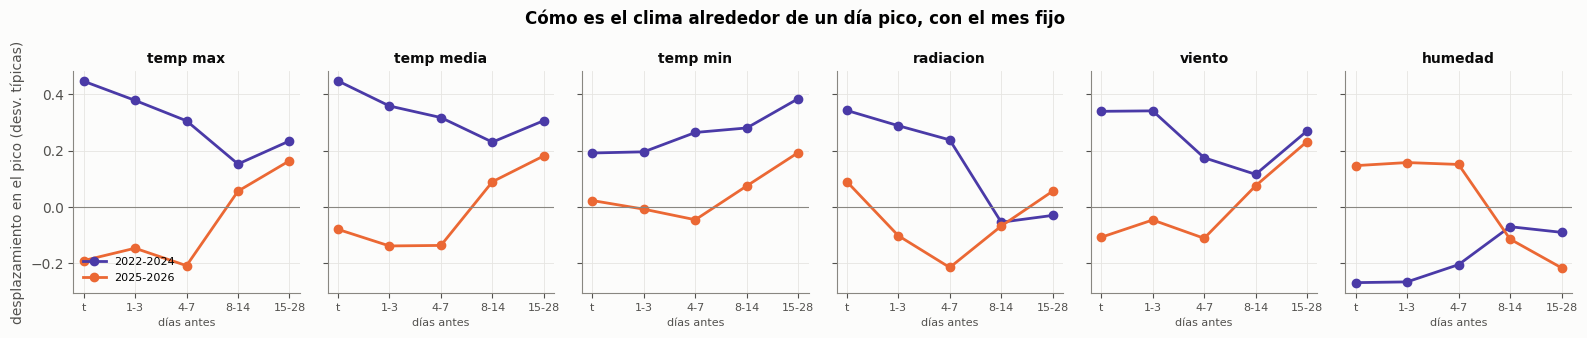

,2022,2023,2024,2025,2026
"desplazamiento en el pico, por año",,,,,
temp_max|t,0.26,0.26,0.32,-0.18,-0.09
radiacion|t,0.27,0.27,0.42,0.06,0.28
temp_min|t-15a28,-0.16,0.03,0.07,0.05,0.06
viento|t-15a28,0.02,-0.09,0.02,0.03,0.28


In [9]:
VARS = ["temp_max", "temp_media", "temp_min", "radiacion", "viento", "humedad"]
VV = list(VENT)
fig, axes = plt.subplots(1, len(VARS), figsize=(16, 3.4), sharey=True)
for ax, vname in zip(axes, VARS):
    s = W[(W["var"].str.startswith(vname + "|")) & W.estado.eq("pico")].set_index("var")
    s = s.reindex([f"{vname}|{k}" for k in VV])
    ax.plot(range(5), s.efecto_desc_mes.values, "-o", color=VIOLETA, lw=2, ms=6, label="2022-2024")
    ax.plot(range(5), s.efecto_conf_mes.values, "-o", color=NARANJA, lw=2, ms=6, label="2025-2026")
    ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks(range(5), ["t", "1-3", "4-7", "8-14", "15-28"], fontsize=8)
    ax.set_title(vname.replace("_", " "), fontsize=10); ax.set_xlabel("días antes", fontsize=8)
axes[0].set_ylabel("desplazamiento en el pico (desv. típicas)"); axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Cómo es el clima alrededor de un día pico, con el mes fijo", fontweight="bold"); plt.tight_layout(); plt.show()

por_anio = {}
for vname in ["temp_max|t", "radiacion|t", "temp_min|t-15a28", "viento|t-15a28"]:
    por_anio[vname] = {y: round(prueba(X[vname].rename(vname), (f"{y}-01-01", f"{y}-12-31"))["pico"], 2) for y in range(2022, 2027)}
pd.DataFrame(por_anio).T.rename_axis("desplazamiento en el pico, por año")

In [10]:
# transicion a posteriori (DECLARADA: no estaba preregistrada): mes pasado mas calido que la semana reciente
X["enfriamiento_posthoc"] = X["temp_media|t-15a28"] - (3 * X["temp_media|t-1a3"] + 4 * X["temp_media|t-4a7"]) / 7
pd.DataFrame({per: prueba(X["enfriamiento_posthoc"].rename("enfriamiento_posthoc"), rg) for per, rg in [("2022-2024", DESC), ("2025-2026", CONF)]}).T.round(3)

,pico,p_pico,bajo,p_bajo
2022-2024,-0.098,0.318,0.059,0.535
2025-2026,0.277,0.022,-0.097,0.460


**Lectura.**
- **El «día pico cálido y soleado» es real en 2022, 2023 y 2024:** la temperatura máxima del día da
  +0,26 a +0,32 desviaciones cada año, con el mismo signo. **En 2025 y 2026 se apaga** (−0,18 y
  −0,09).
  - La radiación del mismo día aguanta mejor (+0,27, +0,27, +0,42, +0,06, +0,28): el sol del día
    sigue acompañando a los picos, salvo en 2025.
  - Un efecto que se repite tres años y luego cambia no es azar. **Algo cambió en 2025**, y el
    candidato conocido es la red (Nueva EPS) y el criterio del triage. Si la relación con el día
    soleado era de **acceso** (la gente sale, se mueve, va a consulta), un cambio en quién entra al
    SES la altera.
- **Lo «confirmado» (calor y viento de hace 15-28 días) no aguanta año por año.** Da cerca de cero en
  cada año, salvo el viento en 2026 (+0,28). La confirmación sale de diferencias **entre** años y
  de un solo año, no de la dinámica de días. **No se toma como hallazgo**: el criterio
  preregistrado lo deja pasar y la comprobación por año lo desmonta.
- **Lo más interesante está en la forma de la curva naranja (2025-2026):** mes pasado **cálido y
  seco**, semana reciente **fresca y húmeda**. Es la **transición** del ejemplo del propietario.
  - La prueba a posteriori (declarada) da **+0,28 (p = 0,02) en 2025-2026** y −0,10 en 2022-2024.
  - Solo aparece en un periodo y no estaba preregistrada, así que **es una hipótesis, no un
    hallazgo**. Si se quiere perseguir, se preregistra con su definición y se confirma en datos que
    no se hayan mirado: 2026-09 en adelante.

---
# 7. Lectura provisional, para conversar

**Lo que ya se puede afirmar a nivel día:**
1. **El calendario es el 72 % de la historia diaria.** Lo que queda (ruido del 10,6 %) se reparte
   parejo en la semana.
2. **Un pico es la demanda entera que se corre**, no un grupo que llega: todas las bandas de edad
   suben a la vez. Eso apunta a **acceso y red**, no a epidemia.
3. **La estación sobrevive al calendario:** mayo es el mes de picos (30 %); febrero, octubre y
   diciembre, de bajos.
4. **La agitación es festiva o institucional:** diciembre-enero, y los trimestres en que se movía la
   red (2025-T4: 63 %).
5. **Ninguna fuente externa anticipa de forma estable los estados del día.** El clima tenía una
   firma clara, que era de acceso y del mismo día, **y se rompió en 2025**.
6. **Hay memoria corta:** un pico duplica la probabilidad de otro al día siguiente (29 % contra
   15 %).

**Preguntas abiertas para decidir entre los dos:**
- **A.** ¿Vale la pena medir si el clima vuelve a mover el triage **dentro de cada asegurador**? Si
  el cambio de 2025 es Nueva EPS, los no-Nueva EPS deberían conservar la firma.
- **B.** Si a nivel día solo quedan calendario, estación, red y memoria corta, ¿el primer modelo se
  arma con eso como **base honesta**, y lo externo entra solo si mejora fuera de muestra?
- **C.** ¿Se prueba el mismo enfoque de estados sobre la **serie respiratoria** (cuaderno 10), que
  es donde el entorno sí se ve (cuaderno 13)?

*(Esta sección se completa con lo que se concluya en la conversación.)*